# Phase 2: Exploratory analysis and hypothesis tests

**Goal:** understand delivery, reviews and repeat purchasing before modelling, and back each business claim with a statistical test.

**Questions**
1. How big is the business, and how often do customers come back?
2. How reliable is delivery, and where is it worst?
3. Does late delivery hurt review scores? (H1, H2)
4. Does a bad first experience make customers less likely to return? (H3, H4)
5. Does delivery time differ by state? (H5)

Data: `data/processed/orders_enriched.parquet` from Phase 1, restricted to orders before 2018-09-01 (the last weeks of the dataset are an incomplete tail; see `src/customers.py`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.customers import DATA_END, RETURN_WINDOW_DAYS, first_orders_with_return_flag, load_orders, load_purchases
from src.stats_tests import chi_square_2x2, holm_adjust, kruskal_by_group, mann_whitney

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

orders = load_orders()
purchases = load_purchases(orders)
delivered = orders[(orders["order_status"] == "delivered") & orders["is_late"].notna()].copy()
print(f"orders: {len(orders):,} | purchases: {len(purchases):,} | delivered with known timing: {len(delivered):,}")

orders: 99,421 | purchases: 98,206 | delivered with known timing: 96,470


## 1. Business overview and repeat purchasing

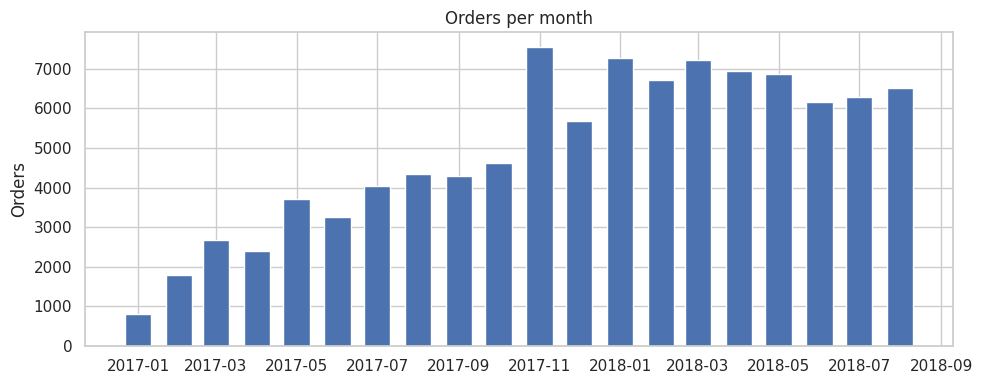

customers: 94,990
customers with more than one purchase: 3.0%
total revenue (payments): R$16,003,843


In [2]:
monthly = orders.set_index("order_purchase_timestamp").resample("MS").agg(
    orders=("order_id", "size"), revenue=("payment_total", "sum"))
monthly = monthly[monthly.index >= "2017-01-01"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly["orders"], width=20, color="#4C72B0")
ax.set(title="Orders per month", ylabel="Orders", xlabel="")
fig.tight_layout(); fig.savefig(FIG / "02_orders_per_month.png", dpi=150); plt.show()

per_customer = purchases.groupby("customer_unique_id").size()
print(f"customers: {len(per_customer):,}")
print(f"customers with more than one purchase: {(per_customer > 1).mean():.1%}")
print(f"total revenue (payments): R${orders['payment_total'].sum():,.0f}")

In [3]:
first = first_orders_with_return_flag(purchases)
print(f"customers whose {RETURN_WINDOW_DAYS}-day window is fully observable: {len(first):,}")
print(f"came back within {RETURN_WINDOW_DAYS} days: {first['returned_within_window'].mean():.2%}")

customers whose 180-day window is fully observable: 57,575
came back within 180 days: 1.97%


**Takeaway:** Olist is overwhelmingly a one-time-purchase marketplace: only about 2 in 100 customers come back within 180 days. That shapes Phase 3: "churn" is the normal outcome, and the business value is in spotting the rare customers likely to return (or the ones worth a retention offer).

## 2. Delivery reliability

late rate (delivered after estimate): 6.8%
median delivery days: 10
median days delivered *before* the estimate: 12


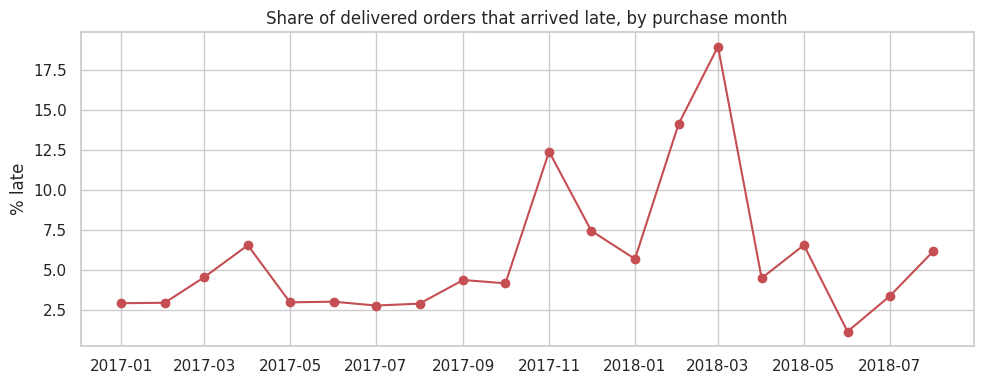

In [4]:
print(f"late rate (delivered after estimate): {delivered['is_late'].mean():.1%}")
print(f"median delivery days: {delivered['delivery_days'].median():.0f}")
print(f"median days delivered *before* the estimate: {-delivered['delay_days'].median():.0f}")

late_month = delivered.set_index("order_purchase_timestamp")["is_late"].astype(float).resample("MS").mean()
late_month = late_month[late_month.index >= "2017-01-01"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(late_month.index, late_month.values * 100, marker="o", color="#C44E52")
ax.set(title="Share of delivered orders that arrived late, by purchase month", ylabel="% late", xlabel="")
fig.tight_layout(); fig.savefig(FIG / "02_late_rate_by_month.png", dpi=150); plt.show()

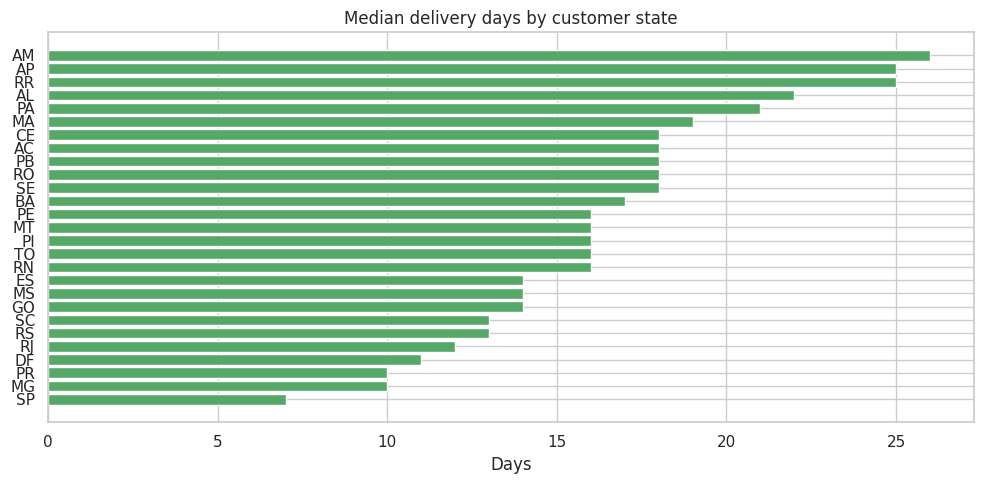

,orders,median_days,late_rate
customer_state,,,
AL,397,22.000,0.214
MA,717,19.000,0.174
SE,335,18.000,0.152
PI,476,16.000,0.139
CE,1279,18.000,0.138
RR,41,25.000,0.122
BA,3256,17.000,0.122
RJ,12350,12.000,0.121


In [5]:
by_state = (delivered.groupby("customer_state")
            .agg(orders=("order_id", "size"), median_days=("delivery_days", "median"), late_rate=("is_late", "mean"))
            .query("orders >= 30").sort_values("median_days"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(by_state.index, by_state["median_days"], color="#55A868")
ax.set(title="Median delivery days by customer state", xlabel="Days", ylabel="")
fig.tight_layout(); fig.savefig(FIG / "02_delivery_days_by_state.png", dpi=150); plt.show()
by_state.sort_values("late_rate", ascending=False).head(8)

**Takeaway:** Olist's delivery estimates are padded: the typical order arrives well before the estimated date, yet a minority still arrive late. Late deliveries spike in specific months (peak season around Nov 2017 and early 2018), and delivery time is strongly regional: south-east states such as SP are fastest, northern states are slowest.

## 3. Delivery experience and review scores

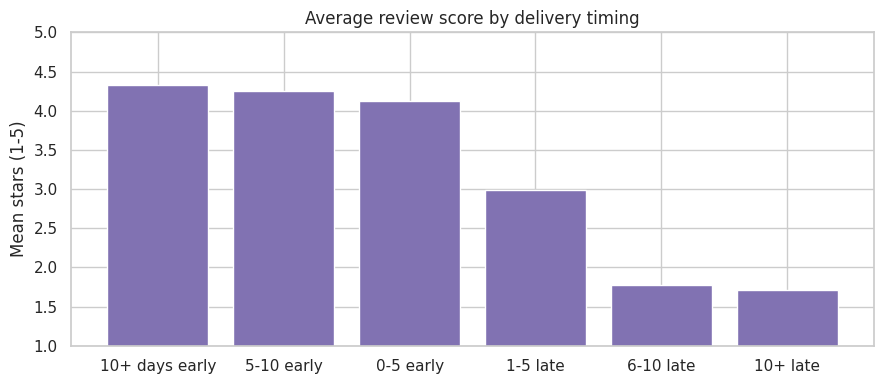

,mean,size
delay_days,,
10+ days early,4.323,61849
5-10 early,4.256,20135
0-5 early,4.120,7952
1-5 late,2.988,2770
6-10 late,1.771,1672
10+ late,1.709,2092


In [6]:
buckets = pd.cut(delivered["delay_days"], [-1000, -10, -5, 0, 5, 10, 1000],
                 labels=["10+ days early", "5-10 early", "0-5 early", "1-5 late", "6-10 late", "10+ late"])
score_by_delay = delivered.groupby(buckets, observed=True)["review_score"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(score_by_delay.index.astype(str), score_by_delay["mean"], color="#8172B2")
ax.set(title="Average review score by delivery timing", ylabel="Mean stars (1-5)", ylim=(1, 5))
fig.tight_layout(); fig.savefig(FIG / "02_review_by_delay.png", dpi=150); plt.show()
score_by_delay

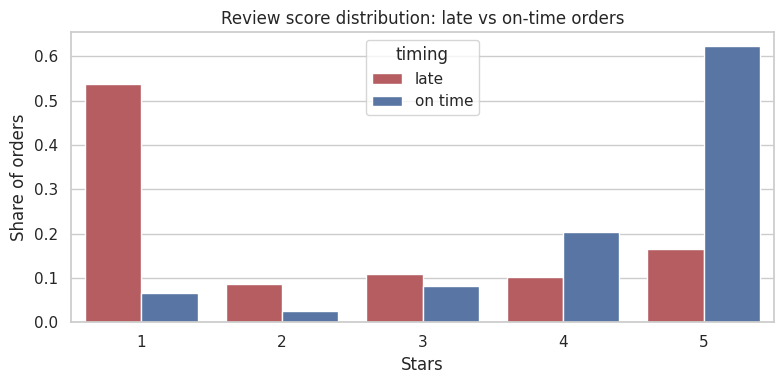

In [7]:
dist = (delivered.dropna(subset=["review_score"])
        .assign(timing=lambda d: d["is_late"].map({True: "late", False: "on time"}))
        .groupby("timing")["review_score"].value_counts(normalize=True).rename("share").reset_index())
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=dist, x="review_score", y="share", hue="timing", palette=["#C44E52", "#4C72B0"], ax=ax)
ax.set(title="Review score distribution: late vs on-time orders", xlabel="Stars", ylabel="Share of orders")
fig.tight_layout(); fig.savefig(FIG / "02_review_distribution_late_vs_ontime.png", dpi=150); plt.show()

## 4. Hypothesis tests

| | Null hypothesis (H0) | Test |
|---|---|---|
| H1 | Late and on-time orders have the same review-score distribution | Mann-Whitney U |
| H2 | Late delivery is unrelated to giving a 1-2 star review | Chi-square |
| H3 | A late *first* order is unrelated to returning within 180 days | Chi-square |
| H4 | A 1-2 star *first* review is unrelated to returning within 180 days | Chi-square |
| H5 | Delivery time is the same across customer states | Kruskal-Wallis |

Significance level 0.05, with a **Holm-Bonferroni** correction because five tests are run together. With this much data, tiny differences become "significant", so the effect size is what decides whether a finding matters.

In [8]:
rated = delivered.dropna(subset=["review_score"])
first_delivered = first[(first["order_status"] == "delivered") & first["is_late"].notna()]
first_rated = first.dropna(subset=["review_score"])

results = pd.DataFrame([
    mann_whitney(rated.loc[rated["is_late"] == True, "review_score"], rated.loc[rated["is_late"] == False, "review_score"],
                 "H1: late delivery -> lower review score", "late", "on time"),
    chi_square_2x2(rated["is_late"], rated["review_score"] <= 2,
                   "H2: late delivery -> 1-2 star review", "late", "on time"),
    chi_square_2x2(first_delivered["is_late"], first_delivered["returned_within_window"],
                   "H3: late first order -> return within 180d", "late first order", "on-time first order"),
    chi_square_2x2(first_rated["review_score"] <= 2, first_rated["returned_within_window"],
                   "H4: 1-2 star first review -> return within 180d", "1-2 star first review", "3-5 star first review"),
    kruskal_by_group(delivered["delivery_days"], delivered["customer_state"],
                     "H5: delivery days differ by state"),
])
results["p_holm"] = holm_adjust(results["p_value"].tolist())
results["reject_H0"] = results["p_holm"] < 0.05
results.to_csv(ROOT / "reports" / "phase2_hypothesis_tests.csv", index=False)
results[["hypothesis", "group_a", "group_b", "n_a", "n_b", "value_a", "value_b", "effect_size", "effect_size_name", "p_holm", "reject_H0"]]

,hypothesis,group_a,group_b,n_a,n_b,value_a,value_b,effect_size,effect_size_name,p_holm,reject_H0
0,H1: late delivery -> lower review score,late,on time,6381,89443,2.270,4.290,-0.638,rank-biserial r,0.000,True
1,H2: late delivery -> 1-2 star review,late,on time,6381,89443,0.624,0.093,6.735,relative risk (Cramer's V = 0.396),0.000,True
2,H3: late first order -> return within 180d,late first order,on-time first order,3927,52491,0.016,0.020,0.785,relative risk (Cramer's V = 0.008),0.069,False
3,H4: 1-2 star first review -> return within 180d,1-2 star first review,3-5 star first review,8329,48774,0.016,0.020,0.794,relative risk (Cramer's V = 0.010),0.024,True
4,H5: delivery days differ by state,fastest: SP,slowest: AM,40494,145,7.000,26.000,0.249,epsilon-squared (27 groups),0.000,True


### Reading the results

`value_a` / `value_b` are mean stars (H1), share of orders or customers with the outcome (H2-H4), or median delivery days (H5).

- **H1, H2 — strong evidence, large effect.** Late orders average about 2.3 stars versus 4.3 for on-time orders, and are roughly 6-7x more likely to get a 1-2 star review. Delivery reliability is the single clearest driver of customer satisfaction in this data.
- **H3 — not significant.** Customers whose first order arrived late came back slightly less often (about 1.6% vs 2.0%), but with so few returners the difference could be chance (p ≈ 0.07). We can't claim late delivery reduces repeat purchases.
- **H4 — significant but small.** A 1-2 star first review is linked to a lower return rate (about 1.6% vs 2.0%, relative risk ≈ 0.8), but the effect size is tiny. Satisfaction matters, but most customers don't return regardless.
- **H5 — strong regional effect.** State explains about a quarter of the variation in delivery time (epsilon-squared ≈ 0.25); the slowest states take several times longer than São Paulo.

### Implications for later phases
- **Phase 3:** the return rate is ~2%, so the model must handle extreme class imbalance and be judged on precision, recall and PR-AUC, not accuracy. Delivery and review features may help only a little (H3, H4), so behavioural features (recency, frequency, spend) will likely matter more.
- **Phase 4:** delivery delay is predictable from geography (H5), which supports the delivery-delay regression.
- **Phase 6:** low reviews cluster on late orders, so delivery complaints should be a major theme in the review text.

*Caveat:* these are associations in observational data, not proof of causation. A late order might also be a bulky or remote order, and those customers may differ in other ways. Phase 7's A/B test design is how a business would test a causal effect.